# ETTm1: структура данных и диагностика гибрида

Цель — исследовать структуру каналов и проверить, что остаётся в одношаговых ошибках
ARIMA, которые получает гибрид. Используется тот же срез ETTm1 и те же разбиения,
что в benchmark. Основной анализ — **train**, проверка переноса — **validation**.
Test закрыт по умолчанию; включение `INCLUDE_TEST` означает post-hoc анализ.

Каналы NPY обозначены номерами: физические названия и календарные метки не восстановлены.
Частота 15 минут взята из конфигурации. Существующие test-результаты моделей здесь
не пересчитываются; Chronos и TimesFM не загружаются.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/tshybrid").is_dir() and (p / "pyproject.toml").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Откройте ноутбук из time-series-hybrid или его notebooks.")
sys.path.insert(0, str(ROOT / "src"))
from tshybrid.exploration import (
    load_catalog, inventory, channel_profile, train_reference, split_arrays, split_drift,
    autocorrelations, spectral_peaks, seasonal_profile, naive_validation, arima_train_diagnostics,
)

CONFIG = ROOT / "configs/benchmark.yaml"
INCLUDE_TEST = False  # True: отдельный post-hoc анализ; не использовать для подбора моделей.
config, catalog = load_catalog(CONFIG)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .2})
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)

DATASET = "ETTm1"
item = catalog[DATASET]
CHANNEL = "0"  # Первый канал, без выбора по качеству моделей.
CONTEXT = 336
WARMUP = 128
HORIZONS = [48, 96]
ARIMA_ORDER = (2, 0, 0)  # Фиксируем вариант из прежнего эксперимента, не подбираем здесь.
N_ARIMA_ORIGINS = 16  # Равномерные окна внутри train; это диагностика, не полный benchmark.
EXPORT = ROOT / "outputs/dataset-exploration/ettm1"

EXPORT.mkdir(parents=True, exist_ok=True)
def save_plot(fig, name):
    fig.tight_layout()
    fig.savefig(EXPORT / name, dpi=140, bbox_inches="tight")
    plt.show()
    plt.close(fig)

def save_table(frame, name):
    frame.to_csv(EXPORT / name, index=False)
    return frame

(EXPORT / "settings.json").write_text(json.dumps({
    "config": str(CONFIG.relative_to(ROOT)), "include_test": INCLUDE_TEST,
    "split_boundaries": {name: {"train_end": item["train_end"], "val_end": item["val_end"],
                               "used_rows": len(item["raw"])} for name, item in catalog.items()},
    "numpy": np.__version__, "pandas": pd.__version__,
}, ensure_ascii=False, indent=2), encoding="utf-8")
print("Экспорт:", EXPORT)

mean, scale = train_reference(item)
train = np.asarray(item["raw"][:item["train_end"]])
ztrain = (train-mean)/scale
period = int(item["spec"]["seasonality"])
channel_index = item["channels"].index(CHANNEL)
display(inventory({DATASET: item}))
(EXPORT / "arima_settings.json").write_text(json.dumps({
    "context": CONTEXT, "warmup": WARMUP, "horizons": HORIZONS,
    "order": ARIMA_ORDER, "n_origins": N_ARIMA_ORIGINS, "channel": CHANNEL,
}, indent=2), encoding="utf-8")

Экспорт: C:\workspace\learning\research\time-series-hybrid\outputs\dataset-exploration\ettm1


,dataset,file,original_rows,used_rows,channels,frequency,seasonality,train,validation,test
0,ETTm1,ETTm1.npy,69680,57600,7,15min,96,34560,11520,11520


148

## Качество каждого канала

Показываем все каналы и доступные split. Выбросы отмечаем по train-квартилям,
не удаляем и не заменяем. Постоянные участки и нули могут быть свойствами процесса.
`repeat_pct` — точные повторы соседних конечных значений.

In [2]:
profile = save_table(channel_profile(item, INCLUDE_TEST), "channel_profiles.csv")
display(profile)

,split,channel,n,nonfinite_pct,mean,std,min,median,max,zero_pct,repeat_pct,outside_train_fence_pct,constant
0,train,0,34560,0.0,7.9900,5.8331,-19.357,8.640,24.180,0.8536,7.0228,2.9774,False
1,train,1,34560,0.0,2.0387,2.0896,-3.550,1.942,9.109,3.6256,12.7318,0.0000,False
2,train,2,34560,0.0,5.1099,5.5190,-22.103,6.005,18.087,0.9983,5.8161,4.5370,False
3,train,3,34560,0.0,0.7562,1.9242,-4.904,0.853,7.178,2.0284,8.9123,0.0000,False
4,train,4,34560,0.0,2.8047,1.0406,-1.188,2.619,8.163,0.6858,11.9737,0.3096,False
5,train,5,34560,0.0,0.7912,0.6324,-1.371,0.914,3.046,0.7321,24.3902,3.0440,False
6,train,6,34560,0.0,17.1250,9.1730,-4.221,15.758,46.007,0.1360,10.4285,0.0000,False
7,validation,0,11520,0.0,6.4849,7.2930,-21.568,7.904,23.108,0.1649,4.9136,4.9479,False
8,validation,1,11520,0.0,1.5464,2.2292,-5.693,1.273,10.315,2.4740,9.7925,0.0000,False
9,validation,2,11520,0.0,3.4340,7.2408,-23.986,5.010,17.767,0.1997,4.0021,9.3663,False


## Тренды и локальная изменчивость на train

На графиках исходные единицы каждого канала. Скользящее среднее и стандартное
отклонение используют только прошлые 96 значений — один предполагаемый день.
Прореживание касается только отрисовки. Резкие изменения проверяем как наблюдаемые
особенности, без автоматического удаления.

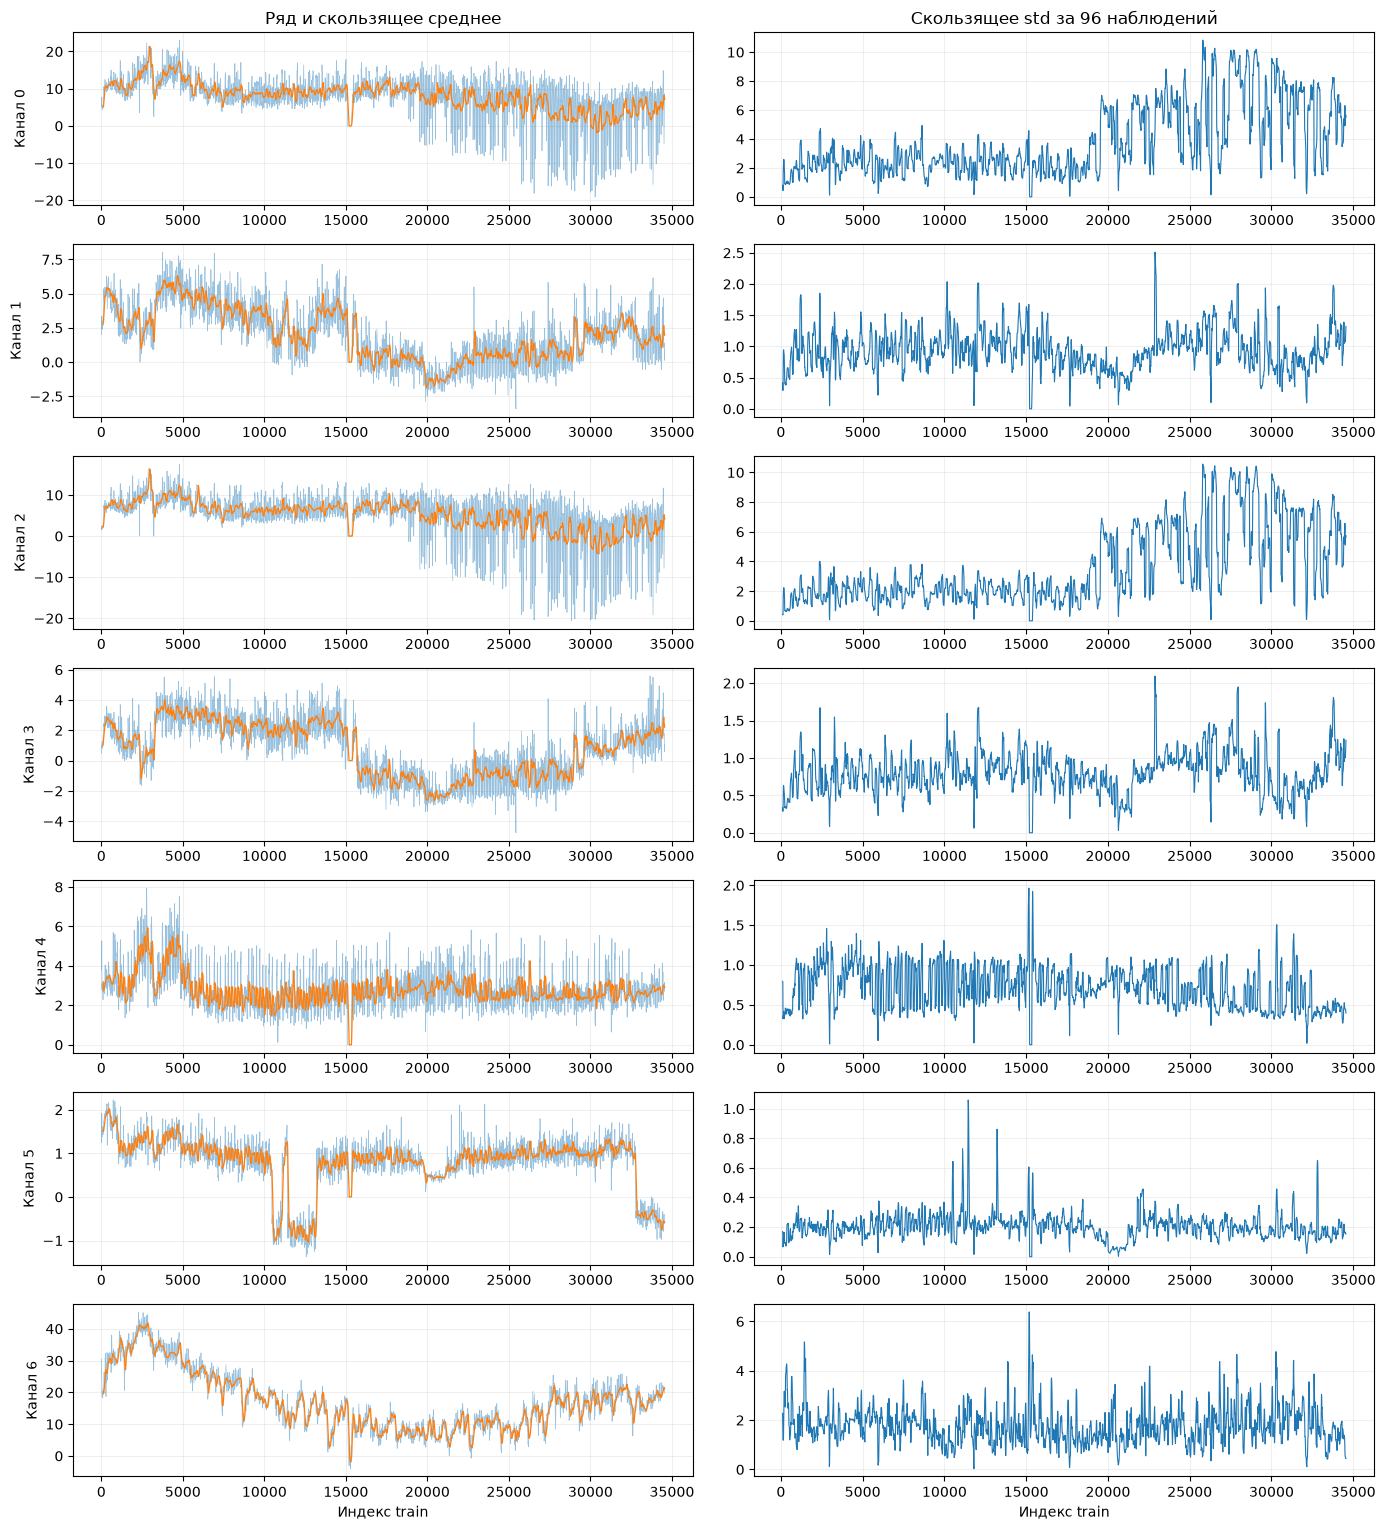

In [3]:
rolling = pd.DataFrame(train, columns=item["channels"]).rolling(period, min_periods=period)
rolling_mean, rolling_std = rolling.mean(), rolling.std(ddof=0)
fig, axes = plt.subplots(len(item["channels"]), 2, figsize=(14, 2.2*len(item["channels"])))
step = max(1, len(train)//2500)
for j, channel in enumerate(item["channels"]):
    axes[j, 0].plot(np.arange(0, len(train), step), train[::step, j], alpha=.45, lw=.5)
    axes[j, 0].plot(rolling_mean.iloc[::step].index, rolling_mean.iloc[::step, j], lw=.9)
    axes[j, 0].set(ylabel=f"Канал {channel}", title="Ряд и скользящее среднее" if j == 0 else "")
    axes[j, 1].plot(rolling_std.iloc[::step].index, rolling_std.iloc[::step, j], lw=.8)
    if j == 0:
        axes[j, 1].set_title("Скользящее std за 96 наблюдений")
for ax in axes[-1]:
    ax.set_xlabel("Индекс train")
save_plot(fig, "train_rolling_statistics.png")

## Автокорреляция и спектр

Сравниваем исходные ряды и первые разности. Это помогает отличить медленные изменения
уровня от повторяемости, но не заменяет формальный анализ стационарности.
Спектр вычисляется на всём train после удаления линейного тренда. Соседние спектральные
пики могут относиться к одному широкому пику; периоды не являются независимыми находками.

lag                1       4       24      48      96      192     336     672
series channel                                                                
diff1  0       -0.1550  0.0624 -0.0324 -0.0046  0.1378  0.1382 -0.0030  0.1398
       1       -0.3125  0.0101 -0.0086 -0.0072  0.0574  0.0803 -0.0023  0.0607
       2       -0.1764  0.0568 -0.0339 -0.0118  0.1096  0.1005 -0.0147  0.1226
       3       -0.3144  0.0008 -0.0017 -0.0129  0.0529  0.0530 -0.0017  0.0532
       4       -0.0068 -0.0071  0.0014 -0.0201  0.1327  0.3349 -0.0239  0.2537
       5       -0.2640  0.0007  0.0014 -0.0158  0.0351  0.1191 -0.0172  0.0806
       6        0.0831 -0.0029 -0.0034 -0.0299  0.0498  0.0552 -0.0110  0.0358
raw    0        0.9768  0.9229  0.3069  0.0522  0.7974  0.7406  0.0162  0.6885
       1        0.9675  0.9362  0.7490  0.6745  0.8438  0.8071  0.5892  0.7262
       2        0.9766  0.9255  0.2673 -0.0282  0.8036  0.7387 -0.0467  0.7030
       3        0.9686  0.9390  0.7785  0.7258  0.8669  0.8361  0.6663  0.7754
       4        0.9643  0.8531  0.4172  0.3101  0.3161  0.5629  0.2241  0.3613
       5        0.9848  0.9643  0.8730  0.8142  0.8108  0.7798  0.6208  0.5308
       6        0.9984  0.9929  0.9588  0.9294  0.9275  0.8799  0.8312  0.8398

,channel,rank,period_steps,power_share,period_hours_by_config
0,0,1,96.0000,0.2824,24.0000
1,0,2,95.7341,0.0568,23.9335
2,0,3,96.2674,0.0543,24.0669
3,1,1,96.0000,0.0724,24.0000
4,1,2,48.0000,0.0219,12.0000
5,1,3,32.0000,0.0077,8.0000
6,2,1,96.0000,0.3133,24.0000
7,2,2,95.7341,0.0667,23.9335
8,2,3,96.2674,0.0601,24.0669
9,3,1,96.0000,0.0488,24.0000


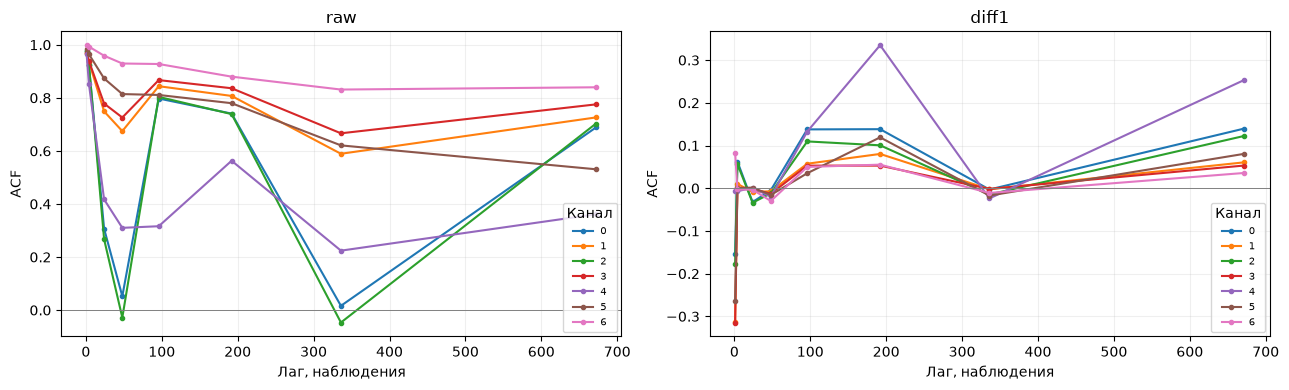

In [4]:
lags = sorted(set([1, 4, 24, 48, 96, 192, 336, 672]))
raw_acf = autocorrelations(train, item["channels"], lags).assign(series="raw")
diff_acf = autocorrelations(np.diff(train, axis=0), item["channels"], lags).assign(series="diff1")
acf_table = save_table(pd.concat([raw_acf, diff_acf], ignore_index=True), "train_acf.csv")
display(acf_table.pivot(index=["series", "channel"], columns="lag", values="acf"))
peaks = spectral_peaks(train, item["channels"], top_n=3, max_period=4*672)
peaks["period_hours_by_config"] = peaks.period_steps*.25
display(save_table(peaks, "train_spectral_peaks.csv"))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, kind in zip(axes, ["raw", "diff1"]):
    for channel, group in acf_table[acf_table.series == kind].groupby("channel"):
        ax.plot(group.lag, group.acf, marker=".", label=channel)
    ax.axhline(0, color="gray", lw=.7)
    ax.set(title=kind, xlabel="Лаг, наблюдения", ylabel="ACF")
    ax.legend(title="Канал", fontsize=7)
save_plot(fig, "raw_and_difference_acf.png")

## Средние сезонные профили

Профили рассчитаны на train после стандартизации по train. Суточная фаза — индекс modulo 96,
недельная — modulo 672. Без временных меток фазу нельзя называть конкретным часом или днём
недели. Усреднение сглаживает различия между циклами и не доказывает устойчивость профиля.

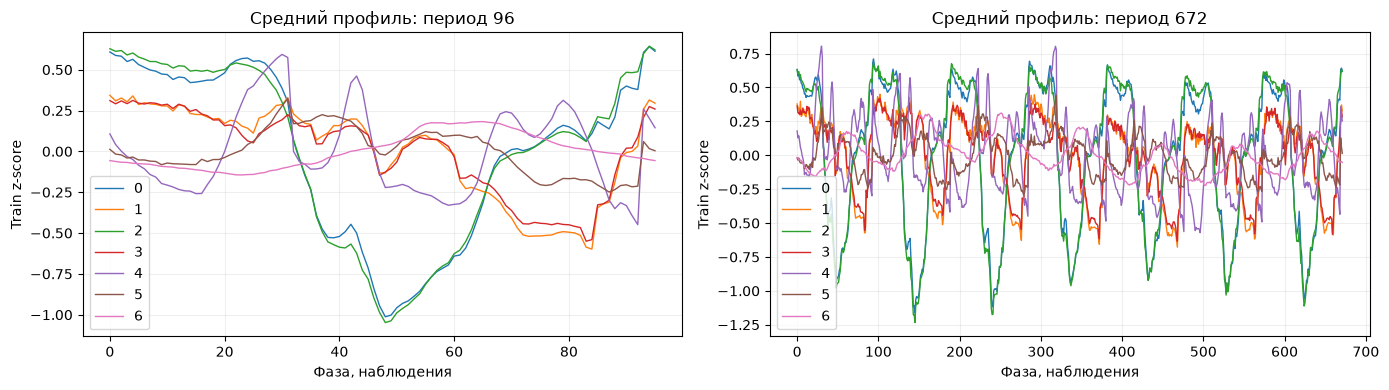

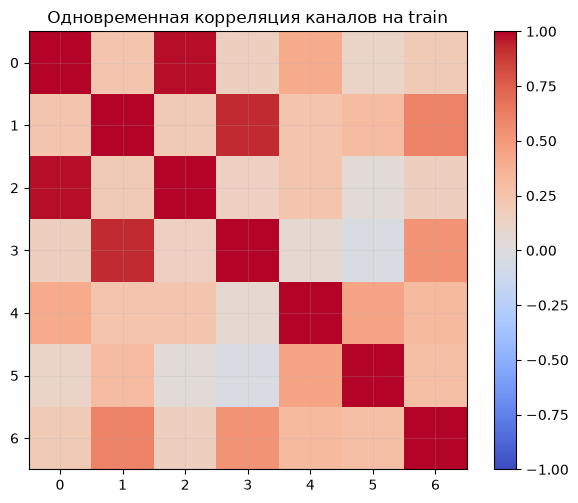

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, cycle in zip(axes, [period, 7*period]):
    seasonal = seasonal_profile(ztrain, cycle)
    seasonal.columns = item["channels"]
    seasonal.plot(ax=ax, lw=1)
    ax.set(title=f"Средний профиль: период {cycle}", xlabel="Фаза, наблюдения", ylabel="Train z-score")
    save_table(seasonal.rename_axis("phase").reset_index(), f"seasonal_profile_{cycle}.csv")
save_plot(fig, "seasonal_profiles.png")
fig, ax = plt.subplots(figsize=(6, 5))
corr = pd.DataFrame(train, columns=item["channels"]).corr()
image = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(corr)), corr.columns)
ax.set_yticks(range(len(corr)), corr.index)
ax.set_title("Одновременная корреляция каналов на train")
fig.colorbar(image, ax=ax)
save_plot(fig, "train_channel_correlation.png")

## Перенос распределений: train → validation

Здесь проверяем уровень и масштаб. Все преобразования используют параметры train.
При включении test он помечается как post-hoc и выводится отдельно от validation.

,split,channel,mean_shift_train_std,std_ratio_to_train,outside_train_fence_pct
0,train,0,0.0000,1.0000,2.9774
1,train,1,0.0000,1.0000,0.0000
2,train,2,0.0000,1.0000,4.5370
3,train,3,0.0000,1.0000,0.0000
4,train,4,0.0000,1.0000,0.3096
5,train,5,0.0000,1.0000,3.0440
6,train,6,0.0000,1.0000,0.0000
7,validation,0,-0.2580,1.2503,4.9479
8,validation,1,-0.2356,1.0668,0.0000
9,validation,2,-0.3037,1.3120,9.3663


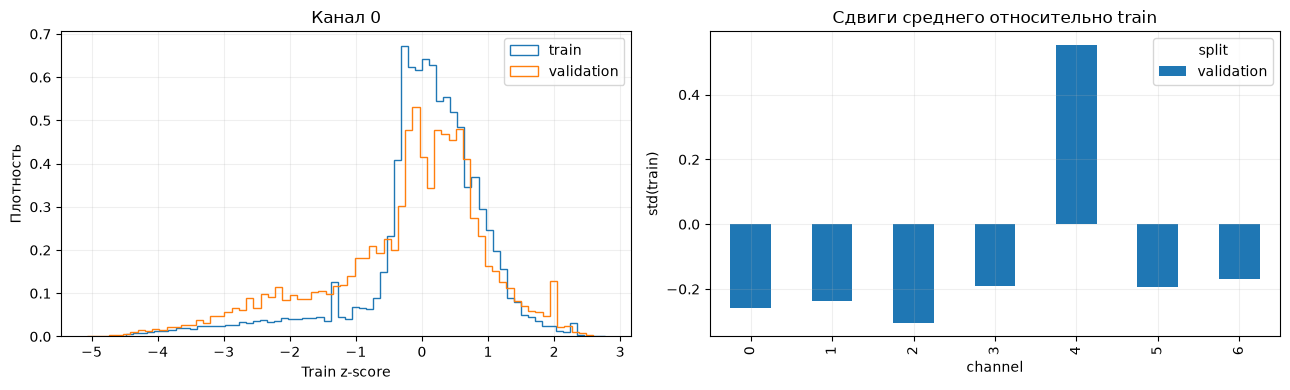

In [6]:
drift = save_table(split_drift(item, INCLUDE_TEST), "split_drift.csv")
display(drift)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for split, values in split_arrays(item, INCLUDE_TEST).items():
    z = (values[:, channel_index]-mean[channel_index])/scale[channel_index]
    axes[0].hist(z[np.isfinite(z)], bins=70, density=True, histtype="step", label=split)
later = drift[drift.split != "train"]
later.pivot(index="channel", columns="split", values="mean_shift_train_std").plot.bar(ax=axes[1])
axes[0].set(title=f"Канал {CHANNEL}", xlabel="Train z-score", ylabel="Плотность")
axes[0].legend()
axes[1].set(title="Сдвиги среднего относительно train", ylabel="std(train)")
save_plot(fig, "split_distributions.png")

## Контекст и горизонты в масштабе данных

При частоте 15 минут контекст 336 — **3,5 суток**, warmup 128 — **32 часа**.
Остаточный контекст гибрида 208 — **52 часа**, то есть около 2,17 суточного цикла.
Горизонты 48/96 — **12/24 часа**. Недельный период 672 не помещается в исходный контекст.
Это ограничения доступной истории, а не доказательство необходимости увеличить контекст.

In [7]:
display(pd.DataFrame({"component": ["context", "warmup", "residual context", "H48", "H96", "week"],
                      "steps": [CONTEXT, WARMUP, CONTEXT-WARMUP, 48, 96, 672]})
        .assign(hours=lambda frame: frame.steps*.25))
baseline = save_table(naive_validation(item, HORIZONS), "validation_naive_by_channel.csv")
display(baseline.groupby(["horizon", "model"])[["mse", "mae"]].mean())
display(baseline.pivot(index="channel", columns=["horizon", "model"], values="mse"))

,component,steps,hours
0,context,336,84.0
1,warmup,128,32.0
2,residual context,208,52.0
3,H48,48,12.0
4,H96,96,24.0
5,week,672,168.0


mse     mae
horizon model                         
48      persistence     1.4566  0.7020
        seasonal_naive  0.4973  0.4425
96      persistence     1.1963  0.6681
        seasonal_naive  0.4973  0.4425

horizon          48                         96               
model   persistence seasonal_naive persistence seasonal_naive
channel                                                      
0            3.7645         0.6681      2.7712         0.6681
1            0.6908         0.5523      0.6853         0.5523
2            4.1963         0.7024      3.1720         0.7024
3            0.7445         0.5085      0.6949         0.5085
4            0.5384         0.5081      0.7149         0.5081
5            0.2256         0.4556      0.2805         0.4556
6            0.0361         0.0864      0.0552         0.0864

Эти ориентиры рассчитаны на rolling validation с шагом origin, равным горизонту.
Persistence и seasonal naive используют только известную к origin историю.
Их значения нельзя напрямую сопоставлять с ранее сохранёнными **test**-метриками моделей.

## Остатки ARIMA: есть ли структура для модели поправки?

Фиксируем ARIMA(2,0,0), warmup 128 и context 336 из прежнего эксперимента.
Берём 16 равномерно расположенных origin **целиком внутри train**, включая будущие
96 целевых значений. ARIMA обучает параметры на первых 128 значениях контекста,
обновляет состояние на следующих 208 и выдаёт прогноз. Это повторяет механизм гибрида.

ACF остатков считается **отдельно в каждом окне**, затем усредняется по окнам:
конкатенация создала бы ложные связи на границах. Остатки являются одношаговыми ошибками,
а требуемая поправка — ошибкой многошагового прогноза. Они могут иметь разную структуру.
Здесь нет Chronos, дообучения или подбора порядка ARIMA. Небольшая выборка окон
служит диагностике; результаты не являются оценкой моделей на независимом test.

,fits,nonconverged,residual_mean,residual_std,history_std
channel,,,,,
0,16,0,0.0132,0.2047,0.7017
1,16,0,-0.0090,0.2329,0.5371
2,16,0,0.0139,0.1980,0.6962
3,16,0,-0.0094,0.2340,0.4849
4,16,0,-0.0084,0.2491,0.7520
5,16,1,-0.0063,0.1435,0.3913
6,16,0,-0.0086,0.0634,0.2624


lag,1,24,48,96
channel,,,,
0,0.0213,-0.0137,-0.0067,0.1201
1,-0.0656,0.0174,-0.0100,0.0740
2,0.0449,-0.0098,-0.0355,0.1261
3,-0.0678,0.0082,-0.0234,0.0641
4,-0.0839,0.0070,0.0117,0.0561
5,-0.0063,0.0023,-0.0297,0.0222
6,0.1104,0.0662,-0.0149,0.0149


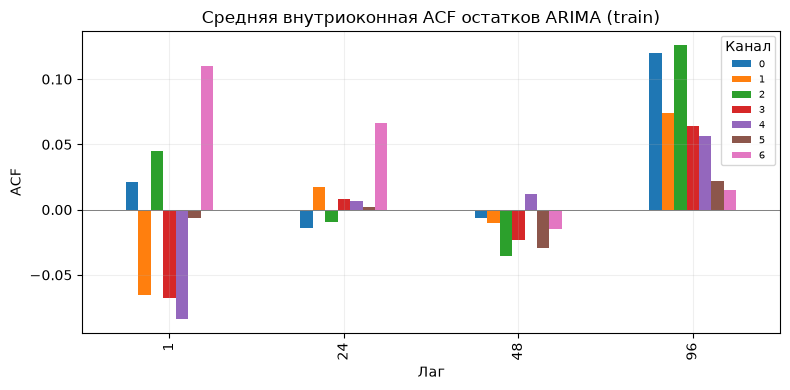

In [8]:
diagnostics = arima_train_diagnostics(item, context=CONTEXT, warmup=WARMUP,
                                     horizon=max(HORIZONS), n_origins=N_ARIMA_ORIGINS,
                                     order=ARIMA_ORDER)
for name, frame in diagnostics.items():
    save_table(frame, f"arima_train_{name}.csv")
fits = diagnostics["fits"]
display(fits.groupby("channel").agg(
    fits=("origin", "size"), nonconverged=("nonconverged", "sum"),
    residual_mean=("residual_mean", "mean"), residual_std=("residual_std", "mean"),
    history_std=("history_std", "mean")))
residual_acf = diagnostics["acf"].groupby(["channel", "lag"]).acf.mean().unstack()
display(residual_acf)
fig, ax = plt.subplots(figsize=(8, 4))
residual_acf.T.plot.bar(ax=ax)
ax.set(title="Средняя внутриоконная ACF остатков ARIMA (train)", xlabel="Лаг", ylabel="ACF")
ax.axhline(0, color="gray", lw=.7)
ax.legend(title="Канал", fontsize=7)
save_plot(fig, "arima_residual_acf.png")

## Простые поправки как диагностический ориентир

Сравниваем ARIMA без поправки, с последним одношаговым остатком и со средним доступных
остатков. Все поправки известны до origin. Если они не помогают, это не доказывает
бесполезность Chronos; проверяется только простейшая переносимость уровня остатков.
Метрики ниже относятся к 96 шагам на выбранных train-окнах, а не ко всему train/validation.

,mse,mae
model,,
ARIMA,0.4402,0.4678
ARIMA + last residual,0.4374,0.4680
ARIMA + mean residual,0.4226,0.4559


mse     mae
channel model                                
0       ARIMA                  0.6641  0.5627
        ARIMA + last residual  0.6907  0.5815
        ARIMA + mean residual  0.6464  0.5513
1       ARIMA                  0.3373  0.4466
        ARIMA + last residual  0.3269  0.4300
        ARIMA + mean residual  0.3153  0.4323
2       ARIMA                  0.6801  0.5423
        ARIMA + last residual  0.6936  0.5444
        ARIMA + mean residual  0.6683  0.5340
3       ARIMA                  0.2468  0.3962
        ARIMA + last residual  0.2624  0.4008
        ARIMA + mean residual  0.2329  0.3834
4       ARIMA                  0.7800  0.6758
        ARIMA + last residual  0.7321  0.6674
        ARIMA + mean residual  0.7637  0.6689
5       ARIMA                  0.2001  0.3509
        ARIMA + last residual  0.2128  0.3764
        ARIMA + mean residual  0.1837  0.3391
6       ARIMA                  0.1729  0.3001
        ARIMA + last residual  0.1437  0.2753
        ARIMA + mean residual  0.1477  0.2824

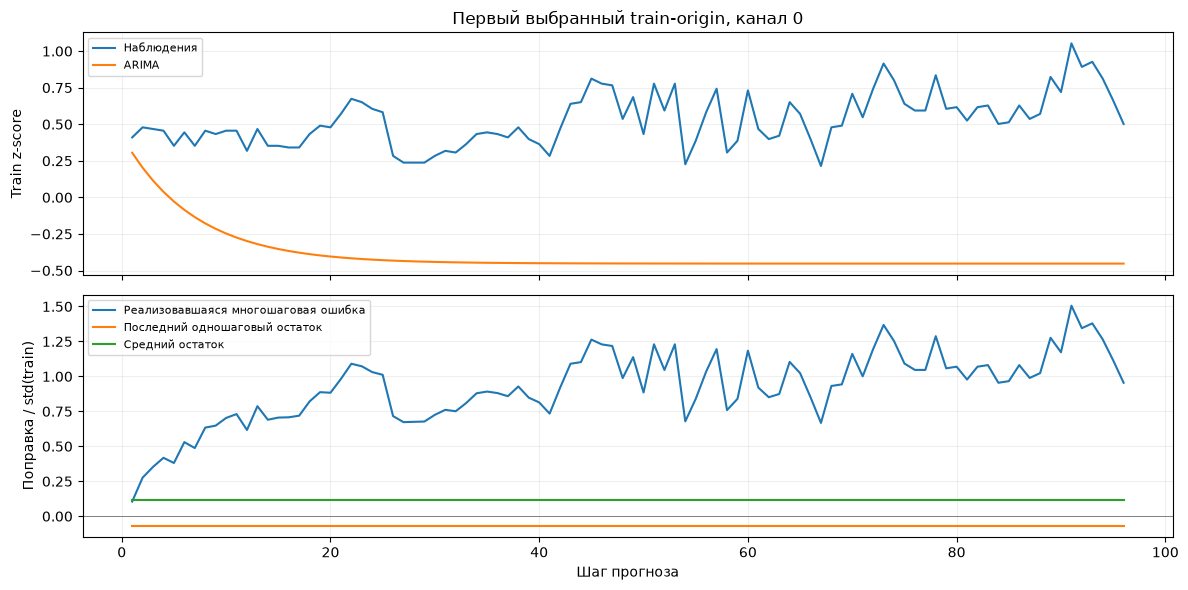

In [9]:
scores = diagnostics["scores"]
display(scores.groupby("model")[["mse", "mae"]].mean())
display(scores.groupby(["channel", "model"])[["mse", "mae"]].mean())
example = diagnostics["example"]
chosen = example[example.channel == CHANNEL]
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(chosen.lead, chosen.truth, label="Наблюдения")
axes[0].plot(chosen.lead, chosen.base, label="ARIMA")
axes[0].set(title=f"Первый выбранный train-origin, канал {CHANNEL}", ylabel="Train z-score")
axes[1].plot(chosen.lead, chosen.required_correction, label="Реализовавшаяся многошаговая ошибка")
axes[1].plot(chosen.lead, chosen.last_residual, label="Последний одношаговый остаток")
axes[1].plot(chosen.lead, chosen.mean_residual, label="Средний остаток")
axes[1].axhline(0, color="gray", lw=.7)
axes[1].set(xlabel="Шаг прогноза", ylabel="Поправка / std(train)")
for ax in axes:
    ax.legend(fontsize=8)
save_plot(fig, "arima_required_and_available_correction.png")

## Наблюдения и границы выводов

Итоги ниже формируются из вычислений. ACF не является доказательством доступной
прогнозной точности, а предупреждения ARIMA не устанавливают причину ошибки.
Проверяемая следующая гипотеза для гибрида: обучать поправку на исторических
многошаговых ошибках по каждому lead, используя только прошлые окна.
Сравнивать варианты следует на validation; для независимой итоговой оценки
после изменений потребуется ещё не использованный временной отрезок.

In [10]:
daily = raw_acf[raw_acf.lag == period].acf.median()
residual_daily = residual_acf[period].median() if period in residual_acf else np.nan
val = drift[drift.split == "validation"]
worst = val.iloc[val.mean_shift_train_std.abs().argmax()]
summary_scores = scores.groupby("model").mse.mean()
best = summary_scores.idxmin()
summary_text = (
    f"- Медианная суточная ACF исходных train-рядов: **{daily:.3f}**.\n"
    f"- Медиана средней внутриоконной ACF остатков на лаге 96: **{residual_daily:.3f}**.\n"
    f"- Максимальный по модулю сдвиг среднего validation: канал **{worst.channel}**, "
    f"**{worst.mean_shift_train_std:+.3f} std(train)**.\n"
    f"- Предупреждения о сходимости: **{fits.nonconverged.sum()} из {len(fits)}** подгонок.\n"
    f"- На диагностических train-окнах минимальная MSE у **{best}**: "
    f"**{summary_scores[best]:.4f}**.\n"
    "- Выборка train-окон не позволяет заключить, какая foundation-модель лучше. "
    "Для этого нужны сопоставимые прогнозные эксперименты."
)
display(Markdown(summary_text))
(EXPORT / "findings.md").write_text(summary_text, encoding="utf-8")

- Медианная суточная ACF исходных train-рядов: **0.811**.
- Медиана средней внутриоконной ACF остатков на лаге 96: **0.064**.
- Максимальный по модулю сдвиг среднего validation: канал **4**, **+0.553 std(train)**.
- Предупреждения о сходимости: **1 из 112** подгонок.
- На диагностических train-окнах минимальная MSE у **ARIMA + mean residual**: **0.4226**.
- Выборка train-окон не позволяет заключить, какая foundation-модель лучше. Для этого нужны сопоставимые прогнозные эксперименты.

487